# Capítulo 3 · Actividad: limpieza de datos y outliers

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/02_actividad_limpieza_outliers.ipynb)

Vas a aplicar lo que viste en la notebook de clase `04_limpieza_y_outliers` a **tres datasets distintos**. Cada uno tiene problemas diferentes, igual que en la vida real.

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```

### Cómo trabajar

- Cada ejercicio tiene una celda `# Tu código aquí`. Añade todas las celdas que necesites.
- En las celdas ✍️ **justifica tus decisiones**: en limpieza de datos casi nunca hay una única respuesta correcta, pero siempre tiene que haber un motivo.
- Al terminar, ejecuta **Kernel → Restart & Run All**.

| Parte | Datos | Tema |
|---|---|---|
| A. Empleados | una tabla pequeña creada en la notebook | Limpieza estructural e imputación |
| B. Pingüinos | `data/penguins.csv` | Valores faltantes |
| C. Viviendas de California | `data/california_housing.csv` | Outliers |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

---
## Parte A · Empleados 👩‍💼

Recursos Humanos te pasa esta tabla, exportada a mano de varias hojas de cálculo. Ejecuta la celda para crearla.

In [2]:
empleados = pd.DataFrame({
    "nombre": ["Ana", "Luis", "Marta", "Luis", "Pedro", "Sofía", "Juan", "Elena",
               "Diego", "Carla", "Raúl", "Elena", "Iván", "Lucía"],
    "departamento": [" ventas", "IT", "it ", "IT", "Ventas", "RRHH", "rrhh", "VENTAS",
                     "It", "ventas ", "IT", "VENTAS", "RRHH", " Rrhh"],
    "edad": [34, np.nan, 29, np.nan, 45, 38, np.nan, 41, 27, np.nan, 52, 41, 31, 36],
    "salario": ["$35,000", "$52,000", "$48,500", "$52,000", "39000", "$41,200", "$37,800",
                "40500", "$47,000", "$36,900", "$61,000", "40500", "$39,900", "$42,300"],
    "fecha_ingreso": ["2019-03-15", "2020-07-01", "2021-01-10", "2020-07-01", "2015-09-30",
                      "2018-11-05", "2022-02-14", "2016-06-20", "2023-04-03", "2021-08-16",
                      "2012-01-09", "2016-06-20", "2019-10-21", "2017-05-02"],
})
empleados

,nombre,departamento,edad,salario,fecha_ingreso
0,Ana,ventas,34.0,"$35,000",2019-03-15
1,Luis,IT,NaN,"$52,000",2020-07-01
2,Marta,it,29.0,"$48,500",2021-01-10
3,Luis,IT,NaN,"$52,000",2020-07-01
4,Pedro,Ventas,45.0,39000,2015-09-30
5,Sofía,RRHH,38.0,"$41,200",2018-11-05
6,Juan,rrhh,NaN,"$37,800",2022-02-14
7,Elena,VENTAS,41.0,40500,2016-06-20
8,Diego,It,27.0,"$47,000",2023-04-03
9,Carla,ventas,NaN,"$36,900",2021-08-16


### Ejercicio 1 · Diagnóstico

Haz el diagnóstico de calidad de `empleados`: tipos de cada columna, valores faltantes, filas duplicadas y cómo están escritas las categorías.

In [3]:
print("Filas y Columnas: ",empleados.shape)

Filas y Columnas:  (14, 5)


In [4]:
print("Columnas y tipo de informacion")
print(empleados.info())

Columnas y tipo de informacion
<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   nombre         14 non-null     str    
 1   departamento   14 non-null     str    
 2   edad           10 non-null     float64
 3   salario        14 non-null     str    
 4   fecha_ingreso  14 non-null     str    
dtypes: float64(1), str(4)
memory usage: 692.0 bytes
None


In [5]:
print("Valores faltantes:")
print(empleados.isna().sum())

Valores faltantes:
nombre           0
departamento     0
edad             4
salario          0
fecha_ingreso    0
dtype: int64


In [6]:
print("Filas repetidas:",empleados.duplicated().sum())

Filas repetidas: 2


In [7]:
for dep in ["departamento"]:
    print(empleados[dep].value_counts(dropna=False),"\n")

departamento
IT         3
RRHH       2
VENTAS     2
 ventas    1
it         1
Ventas     1
rrhh       1
It         1
ventas     1
 Rrhh      1
Name: count, dtype: int64 



In [8]:
print("Valores imposiples o externos")
empleados.describe()

Valores imposiples o externos


,edad
count,10.000000
mean,37.400000
std,7.676805
min,27.000000
25%,31.750000
50%,37.000000
75%,41.000000
max,52.000000


✍️ **Pregunta:** haz una lista de todos los problemas que encontraste.

✍️ **Tu respuesta:** 
- Faltan 4 datos de edades
- Salario y fecha, estan con tipos de datos conflictivos
- Edad consume mas memoria con el tipo de dato actual
- Hay 2 filas repetidas
- Los departamentos estan escritos de forma distinta
- Por lo mismo hay varios datos estadisticos que no se pueden calcular

### Ejercicio 2 · Duplicados

Elimina las filas duplicadas. ¿Cuántas filas quedan?

In [9]:
empleados=empleados.drop_duplicates()
print("Filas actuales:",len(empleados))

Filas actuales: 12


### Ejercicio 3 · Texto inconsistente

Normaliza `departamento` para que queden **exactamente tres** valores: `Ventas`, `IT` y `RRHH` (las siglas, en mayúsculas).

In [10]:
mapa={"Ventas":"Ventas","It":"IT","Rrhh":"RRHH"}
empleados["departamento"]=empleados["departamento"].str.strip().str.capitalize().map(mapa)
empleados["departamento"]

0     Ventas
1         IT
2         IT
4     Ventas
5       RRHH
6       RRHH
7     Ventas
8         IT
9     Ventas
10        IT
12      RRHH
13      RRHH
Name: departamento, dtype: str

### Ejercicio 4 · Tipos de datos

a) Convierte `salario` a número. Ojo: no todos los valores tienen el mismo formato.

b) Convierte `fecha_ingreso` a fecha y crea la columna `año_ingreso`.

c) Comprueba los tipos con `dtypes`.

#### a) Convierte `salario` a número. Ojo: no todos los valores tienen el mismo formato.

In [11]:
empleados["salario"]=(empleados["salario"]
                      .str.replace("$","",regex=False)
                      .str.replace(",","",regex=False))
empleados["salario"]=pd.to_numeric(empleados["salario"])
empleados["salario"]

0     35000
1     52000
2     48500
4     39000
5     41200
6     37800
7     40500
8     47000
9     36900
10    61000
12    39900
13    42300
Name: salario, dtype: int64

#### b) Convierte `fecha_ingreso` a fecha y crea la columna `año_ingreso`.

In [12]:
empleados["fecha_ingreso"]=pd.to_datetime(empleados["fecha_ingreso"])
empleados["año_ingreso"]=empleados["fecha_ingreso"].dt.year

#### c) Comprueba los tipos con `dtypes`

In [13]:
empleados[["salario","fecha_ingreso","año_ingreso"]].dtypes

salario                   int64
fecha_ingreso    datetime64[us]
año_ingreso               int32
dtype: object

### Ejercicio 5 · Imputación

a) Crea una columna `edad_faltante` que indique qué empleados no tenían la edad.

b) Rellena la edad con la **mediana de su departamento**.

c) Comprueba que ya no quedan nulos y muestra la tabla final.

#### a) Crea una columna `edad_faltante` que indique qué empleados no tenían la edad.

In [14]:
empleados["edad_faltante"]=empleados["edad"].isna()

#### b) Rellena la edad con la **mediana de su departamento**.

In [15]:
empleados["edad"]=empleados["edad"].fillna(empleados.groupby("departamento")["edad"].transform("median"))

#### c) Comprueba que ya no quedan nulos y muestra la tabla final.

In [16]:
print("Empleados con edad faltante:",empleados["edad"].isna().sum())
empleados

Empleados con edad faltante: 0


,nombre,departamento,edad,salario,fecha_ingreso,año_ingreso,edad_faltante
0,Ana,Ventas,34.0,35000,2019-03-15,2019,False
1,Luis,IT,29.0,52000,2020-07-01,2020,True
2,Marta,IT,29.0,48500,2021-01-10,2021,False
4,Pedro,Ventas,45.0,39000,2015-09-30,2015,False
5,Sofía,RRHH,38.0,41200,2018-11-05,2018,False
6,Juan,RRHH,36.0,37800,2022-02-14,2022,True
7,Elena,Ventas,41.0,40500,2016-06-20,2016,False
8,Diego,IT,27.0,47000,2023-04-03,2023,False
9,Carla,Ventas,41.0,36900,2021-08-16,2021,True
10,Raúl,IT,52.0,61000,2012-01-09,2012,False


✍️ **Pregunta:** ¿por qué la mediana del departamento y no la mediana de todos los empleados? ¿En qué caso daría igual?

✍️ **Tu respuesta:** Porque en distintos departamentos la edad son diferentes, entonces hubiera alterado los valores existentes para cada departamento

---
## Parte B · Pingüinos 🐧 (valores faltantes)

El archivo `data/penguins.csv` tiene medidas de 344 pingüinos de tres especies. Columnas: `species`, `island`, `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g` y `sex`.

### Ejercicio 6 · Diagnóstico de faltantes

a) Carga los datos en `pinguinos`.

b) Calcula cuántos valores faltan en cada columna y qué porcentaje representan.

c) Muestra las filas que tienen algún valor faltante.

#### a) Carga los datos en `pinguinos`.

In [17]:
pinguinos=pd.read_csv(DATA_DIR/"penguins.csv")


#### b) Calcula cuántos valores faltan en cada columna y qué porcentaje representan.

In [18]:
pd.DataFrame({
    "nulos": pinguinos.isna().sum(),
    "porcentaje":(pinguinos.isna().mean()*100).round(2),
})

,nulos,porcentaje
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20


#### c) Muestra las filas que tienen algún valor faltante.

In [19]:
pinguinos[pinguinos.isna().any(axis=1)]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


✍️ **Pregunta:** ¿ves algún patrón en las filas con faltantes? ¿Faltan los datos de forma parecida en todas?

✍️ **Tu respuesta:** A todas les falta el sexo del pinguino, y tanto la primera como la ultima les faltan los mismos valores 

### Ejercicio 7 · Eliminar o imputar

Hay pingüinos a los que les faltan **todas** las medidas. Elimínalos y comprueba cuántas filas quedan.

In [20]:
pinguinos["medidas_faltan"]=pinguinos["bill_length_mm"].isna()
pinguinos["medidas_faltan"].value_counts()
pinguinos=pinguinos.dropna(subset=["bill_length_mm"])
print("Filas:",len(pinguinos))

Filas: 342


✍️ **Pregunta:** ¿por qué en este caso es mejor eliminar esas filas que imputarlas?

✍️ **Tu respuesta:** Por que les faltan todas las dimensiones, y no tenemos ningun caracter que nos pueda permitir tomar algun otro valor como referencia

### Ejercicio 8 · Dos estrategias para el sexo

Compara dos formas de rellenar `sex`, cada una en una **copia** de `pinguinos`:

a) Con la **moda**.

b) Con una categoría nueva, `"desconocido"`.

Muestra `value_counts()` del resultado en cada caso.

#### a) Con la **moda**.

In [21]:
pinguinos_moda=pinguinos.copy()
moda=pinguinos_moda["sex"].mode()[0]
pinguinos_moda["sex"]=pinguinos_moda["sex"].fillna(moda)
pinguinos_moda["sex"].value_counts()

sex
Male      177
Female    165
Name: count, dtype: int64

#### b) Con una categoría nueva, `"desconocido"`.

In [22]:
pinguinos_cat=pinguinos.copy()
pinguinos_cat["sex"]=pinguinos_cat["sex"].fillna("desconocido")
pinguinos_cat["sex"].value_counts()

sex
Male           168
Female         165
desconocido      9
Name: count, dtype: int64

✍️ **Pregunta:** ¿qué estrategia elegirías aquí y por qué? Fíjate en cuántos machos y hembras hay.

✍️ **Tu respuesta:** Creo que optaria por descnocido, debido a que con la moda, senti que los valores variaron mucho, y descnocido, permite que esas posibles desviaciones se respeten mas

### Ejercicio 9 · Con scikit-learn

Usa `SimpleImputer` para rellenar `sex` con el valor más frecuente. ¿Qué valor aprendió? ¿Coincide con la moda del ejercicio 8?

In [23]:
imputador= SimpleImputer(strategy="most_frequent")
imputador.fit(pinguinos)
print("Valores aprendidos", imputador.statistics_)
pinguinos["sex"].value_counts()

Valores aprendidos ['Adelie' 'Biscoe' 41.1 17.0 190.0 3800.0 'Male' False]


sex
Male      168
Female    165
Name: count, dtype: int64

---
## Parte C · Viviendas de California 🏠 (outliers)

El archivo `data/california_housing.csv` viene del censo de California de 1990. **Cada fila es un distrito** (un barrio), no una vivienda:

| Columna | Significado |
|---|---|
| `MedInc` | ingreso mediano del distrito (en decenas de miles de $) |
| `HouseAge` | antigüedad mediana de las viviendas (años) |
| `AveRooms` | número medio de habitaciones por vivienda |
| `AveBedrms` | número medio de dormitorios por vivienda |
| `Population` | población del distrito |
| `AveOccup` | número medio de personas por vivienda |
| `Latitude`, `Longitude` | ubicación |
| `MedHouseVal` | valor mediano de las viviendas (en cientos de miles de $) |

### Ejercicio 10 · Primer vistazo

Carga los datos en `california` y muestra sus estadísticas descriptivas.

In [24]:
california=pd.read_csv(DATA_DIR/"california_housing.csv")
california.describe()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


✍️ **Pregunta:** ¿en qué columnas el máximo está muy lejos del percentil 75%? ¿Te parece posible algún valor?

✍️ **Tu respuesta:** En casi todas el maximo esta lejos del percentil 75%, creo solo latitude y longitud tiene sentido para mi

### Ejercicio 11 · Detección visual

Dibuja en una misma figura el boxplot de `AveRooms`, `AveOccup` y `Population`, cada uno en su propio gráfico.

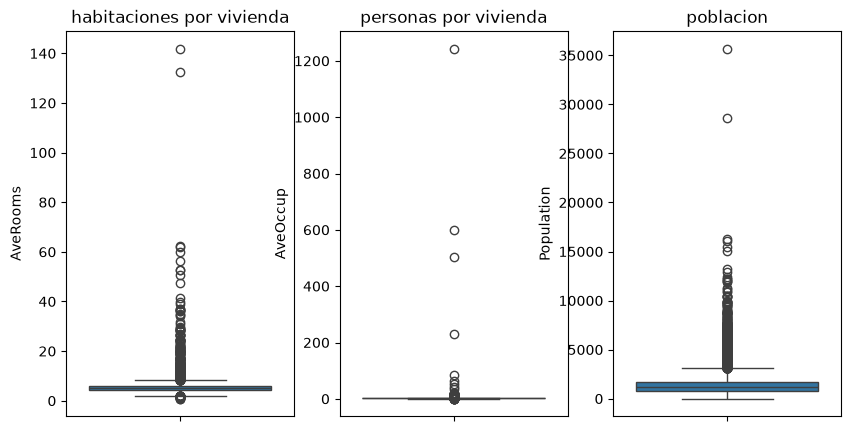

In [25]:
fig,axes=plt.subplots(1,3,figsize=(10,5))
sns.boxplot(data=california,y="AveRooms",ax=axes[0])
axes[0].set_title( "habitaciones por vivienda")

sns.boxplot(data=california,y="AveOccup",ax=axes[1])
axes[1].set_title("personas por vivienda")

sns.boxplot(data=california,y="Population",ax=axes[2])
axes[2].set_title("poblacion")

plt.show()

### Ejercicio 12 · Z-score contra IQR

Para **cada columna** de `california`, cuenta cuántos outliers detecta el z-score ($|z| > 3$) y cuántos el IQR. Junta los resultados en un DataFrame con una fila por columna.

In [26]:
z=(california -california.mean())/california.std()
zoutliers=(z.abs()>3).sum()

q1=california.quantile(0.25)
q3=california.quantile(0.75)
iqr=q3-q1
outlier=q1 - 1.5 * iqr, q3 + 1.5 * iqr 
iqroutlier=((california < outlier[0]) | (california>outlier[1])).sum()

pd.DataFrame({
    "outlier IQR":iqroutlier,
    "outlier Z":zoutliers
})


,outlier IQR,outlier Z
MedInc,681,345
HouseAge,0,0
AveRooms,511,133
AveBedrms,1424,145
Population,1196,342
AveOccup,711,8
Latitude,0,0
Longitude,0,0
MedHouseVal,1071,0


✍️ **Pregunta:** en `AveOccup`, ¿por qué el z-score detecta tan pocos outliers y el IQR tantos? ¿Cuál de los dos números te parece más razonable?

✍️ **Tu respuesta:** El IQR, por lo que se vio en los graficos tipo boxplot, me parece con mas sentido el IQR, probbalemente Z score falla, debido al uso de la media y la desviacion estandar

### Ejercicio 13 · Criterio de negocio

`AveOccup` es el número medio de personas que viven en cada vivienda del distrito.

a) Muestra los 5 distritos con mayor `AveOccup`.

b) Decide un **umbral razonable** por encima del cual el valor no tiene sentido, y elimina esos distritos. ¿Cuántos eliminaste?

In [27]:
california["AveRooms"].sort_values(ascending=False).head()

1914     141.909091
1979     132.533333
12447     62.422222
1913      61.812500
11862     59.875000
Name: AveRooms, dtype: float64

In [28]:
error=california["AveRooms"]>70.00
print(error.sum())
california = california[~error]

2


✍️ **Pregunta:** ¿qué umbral elegiste y por qué?

✍️ **Tu respuesta:** 

Elegi superior a 70, debido a que parece un valor en cercano al maximo actual que no difiere de los otros

### Ejercicio 14 · Winsorización

Winsoriza `AveRooms` en los percentiles 1 y 99, guardando el resultado en una columna nueva `AveRooms_wins`. Compara las estadísticas descriptivas de las dos columnas.

In [29]:
p01, p99 = california["AveRooms"].quantile([0.01, 0.99])
print(f"Percentil 1: {p01:,.0f}    Percentil 99: {p99:,.0f} ")

california["AveRooms_wins"]=california["AveRooms"].clip(lower=p01, upper=p99)
california[["AveRooms","AveRooms_wins"]].describe().round(0)


Percentil 1: 3    Percentil 99: 10 


,AveRooms,AveRooms_wins
count,20638.0,20638.0
mean,5.0,5.0
std,2.0,1.0
min,1.0,3.0
25%,4.0,4.0
50%,5.0,5.0
75%,6.0,6.0
max,62.0,10.0


### Ejercicio 15 · Un caso raro

Muestra los 5 valores más frecuentes de `MedHouseVal`.

In [39]:
california["MedHouseVal"].value_counts().head()

MedHouseVal
5.00001    964
1.37500    122
1.62500    116
1.12500    103
1.87500     93
Name: count, dtype: int64

✍️ **Pregunta:** ¿qué crees que pasó con el valor más repetido? ¿Es un outlier? ¿Qué problema podría causarle a un modelo que intente predecir el valor de las viviendas?

✍️ **Tu respuesta:**

Creo que si se trata de un outlier, por la variacion tan grande que tiene con respecto al resto, podria afectar, debido a que se trata de una gran cantidad de datos, alterando el modelo, aunque si el resto de las caracteristicas corresponden, es mas probable que se trate de casos especiales